## Outliers function and loading df.


In [23]:
%load_ext autoreload 
%autoreload 2

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.insert(0, os.path.abspath('..'))
import src.io_utils as io

df = io.load_data('../data/ecommerce_sales.csv').sort_values('date').set_index('order_id')
print(df.head())

def get_outliers(df, k=3.0):
    q1, q3 = df['revenue'].quantile([0.25, 0.75])
    iqr = q3 - q1
    return df[(df['revenue'] < (q1 - k * iqr)) | (df['revenue'] > (q3 + k * iqr))].sort_values(by='revenue', ascending=False)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
               date       city     category    price  units  revenue
order_id                                                            
101847   2024-01-01  Stockholm     Clothing   309.63      6  1857.78
100120   2024-01-01      Malmö         Home   502.33      2  1004.66
100609   2024-01-01      Malmö     Clothing   480.18      3  1440.54
100516   2024-01-01   Västerås  Electronics  1037.70      4  4150.80
101939   2024-01-01   Göteborg       Sports   315.92      7  2211.44


## Top 10 extremvärden

In [ ]:
print(get_outliers(df).head(5))

               date       city     category    price  units  revenue
order_id                                                            
101411   2024-02-26  Stockholm  Electronics  1838.52      5  9192.60
101339   2024-02-26   Göteborg  Electronics  1703.37      5  8516.85
101491   2024-06-04   Västerås  Electronics  2092.53      4  8370.12
101733   2024-06-05    Uppsala  Electronics  1227.73      6  7366.38
101518   2024-01-12   Göteborg  Electronics  1403.69      5  7018.45
102191   2024-01-02  Stockholm  Electronics  1103.14      6  6618.84
101601   2024-04-15    Uppsala  Electronics  1287.06      5  6435.30
100116   2024-02-10    Uppsala  Electronics  1593.28      4  6373.12
100045   2024-06-17   Västerås       Sports  1052.08      6  6312.48
102282   2024-06-25      Malmö       Sports  1048.89      6  6293.34


## Total intäkt och totalt antal enheter.


In [25]:
df_revenue = df.groupby('city').agg(
    revenue = ('revenue', 'sum'),
    units = ('units', 'sum')
)

df_revenue = df_revenue.sort_values(by='revenue', ascending=False)
df_revenue.loc['Total'] = [df_revenue['revenue'].sum(), df_revenue['units'].sum()]
print(df_revenue.round(1))


             revenue   units
city                        
Stockholm  1227201.9  2619.0
Göteborg    859019.6  1788.0
Malmö       567926.3  1211.0
Uppsala     551478.4  1165.0
Västerås    297140.9   680.0
Total      3502767.2  7463.0


### AOV (Average Order Value).  

In [26]:
print(df['revenue'].mean().round(2))
  

1401.11


### Intäkt per kategori. & Intäkt per stad. (Top-3 kategorier efter intäkt. )


In [27]:
print(
    df.groupby('category').agg(
    Intäkt = ('revenue', 'sum'),
).round(2)
.sort_values(by='Intäkt', ascending=False)
.head(3)
)

print(
    df.groupby('city').agg(
    revenue= ('revenue', 'sum'),
).round(2).sort_values(by='revenue', ascending=False)
)

                 Intäkt
category               
Electronics  1364228.07
Sports        734653.42
Clothing      586744.91
              revenue
city                 
Stockholm  1227201.94
Göteborg    859019.65
Malmö       567926.32
Uppsala     551478.42
Västerås    297140.90


### Medelvärdet av units per order

In [28]:
print(
    df.groupby('category').agg(
    units = ('units', 'mean'),
).round(2)
.sort_values(by='units', ascending=False)
)

             units
category          
Sports        3.38
Clothing      3.25
Toys          3.16
Electronics   2.84
Beauty        2.73
Home          2.61


### Pivot tables med intäkter per kategori och stad. OCH andelar av kategori per stad i %

In [37]:
pivot = pd.pivot_table(
    df,
    index="city",
    columns="category",
    values="revenue",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total",
)
# remakes the columns to % shares
pct_cols  = pivot.div(pivot.loc["Total"], axis=1) * 100
print(pivot.round(0).astype(int))
print()
print(pct_cols.round(1))

category   Beauty  Clothing  Electronics    Home  Sports    Toys    Total
city                                                                     
Göteborg    42693    128566       340629  137852  173114   36165   859020
Malmö       22152     77555       234715   89276  123529   20699   567926
Stockholm   50002    206056       457852  166672  292131   54489  1227202
Uppsala     27956    102400       236363   71514   92308   20938   551478
Västerås    20251     72168        94669   45756   53571   10725   297141
Total      163054    586745      1364228  511071  734653  143016  3502767

category   Beauty  Clothing  Electronics   Home  Sports   Toys  Total
city                                                                 
Göteborg     26.2      21.9         25.0   27.0    23.6   25.3   24.5
Malmö        13.6      13.2         17.2   17.5    16.8   14.5   16.2
Stockholm    30.7      35.1         33.6   32.6    39.8   38.1   35.0
Uppsala      17.1      17.5         17.3   14.0    12.6  

### Intäkt per stad, uppdelat på kategorier

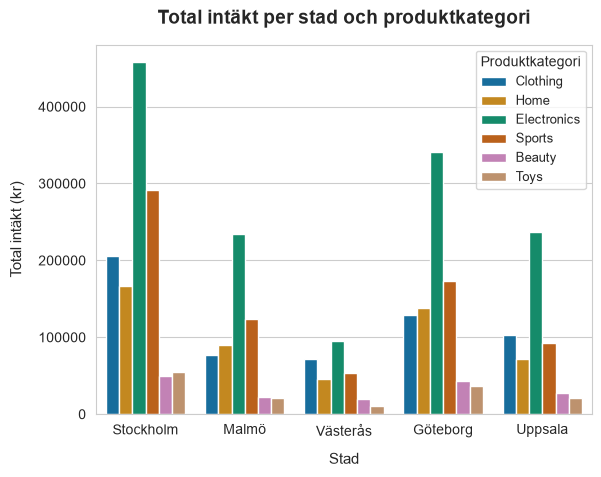

In [30]:
sns.set_style('whitegrid')
sns.barplot(x='city', y='revenue', data=df, palette='colorblind',hue='category', estimator=np.sum, errorbar=None)
plt.title('Total intäkt per stad och produktkategori', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Stad', fontsize=11, labelpad=10)
plt.ylabel('Total intäkt (kr)', fontsize=11, labelpad=10)
plt.legend(title='Produktkategori', fontsize=9, title_fontsize=10)
plt.show()

### Svärmdiagram, enhetspris per kategori, slutsatser ganska bred bas med lågprisprodukter för lägsta priset 50kr

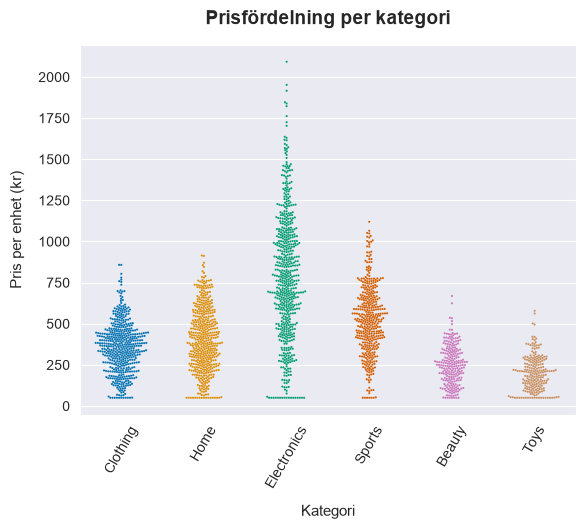

In [31]:
sns.set_style('darkgrid')
sns.swarmplot(x='category', y='price', data=df, size=1.5, hue='category', palette='colorblind')
plt.title('Prisfördelning per kategori', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kategori', fontsize=11, labelpad=10)
plt.ylabel('Pris per enhet (kr)', fontsize=11, labelpad=10)
plt.xticks(rotation=60)
plt.show()

### Intäkt per stad och månad

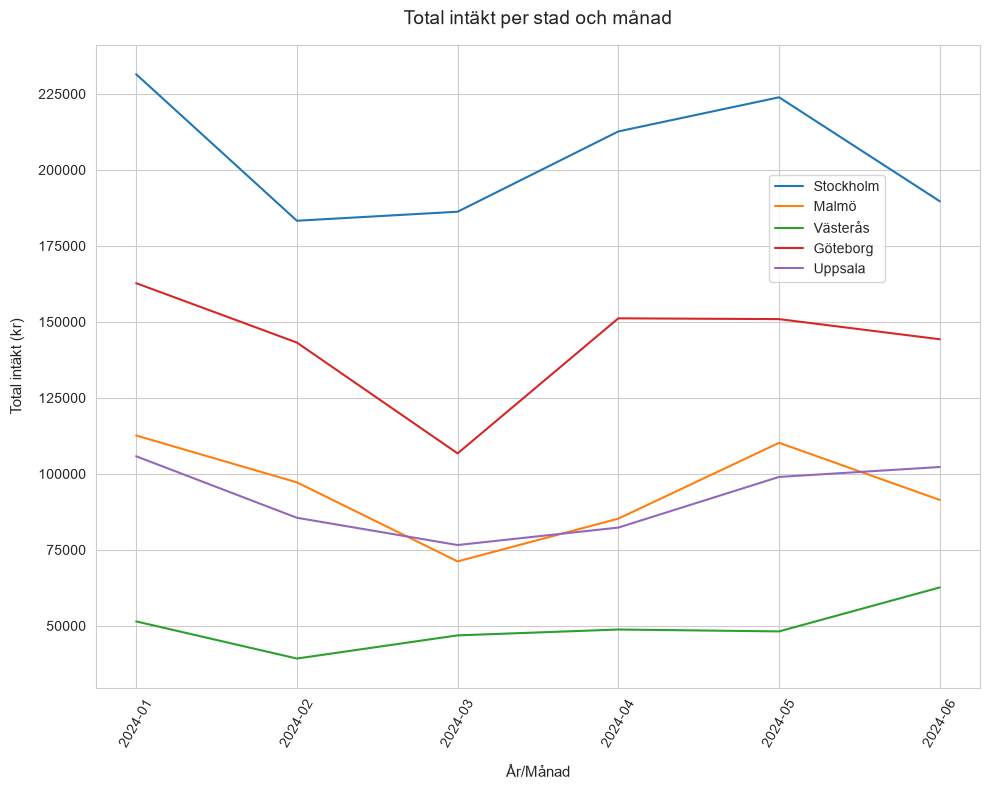

In [32]:
df['year_month'] = df['date'].dt.to_period('M').astype(str)
plt.figure(figsize=(10, 8))
sns.set_style('whitegrid')
sns.lineplot(data=df, x='year_month', y='revenue', hue = 'city', estimator=np.sum, errorbar=None)

# If total is wanted, count Total per month and adds Total line in the plot in black -- line
# df_total = df.groupby('year_month')['revenue'].sum().reset_index()
# sns.lineplot(data=df_total, x='year_month', y='revenue', color='black', linestyle='--', linewidth=3, label='Total')

plt.legend(loc='upper left', bbox_to_anchor=(0.76, 0.8),borderaxespad=0.1)
plt.title('Total intäkt per stad och månad', fontsize=14, pad=15)
plt.xlabel('År/Månad', fontsize=11, labelpad=10)
plt.ylabel('Total intäkt (kr)', fontsize=11, labelpad=10)
plt.xticks(rotation=60) 
plt.tight_layout()   
plt.show()

### Intäkt per kategori och månad

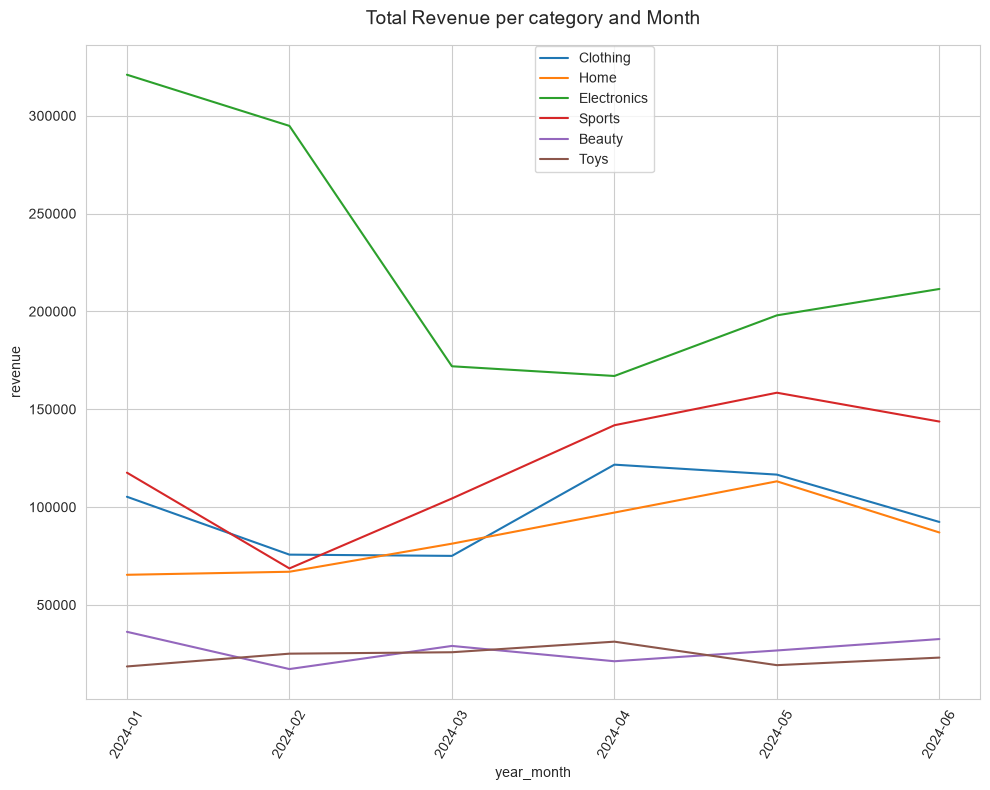

In [33]:
plt.figure(figsize=(10, 8))
sns.lineplot(data=df, x='year_month', y='revenue', hue = 'category', estimator=np.sum, errorbar=None)
sns.set_style('whitegrid')

plt.title('Total Revenue per category and Month', fontsize=14, pad=15)
plt.legend(loc='upper left', bbox_to_anchor=(0.5, 1),borderaxespad=0.1)
plt.xticks(rotation=60) 
plt.tight_layout() 
plt.show()